# Baseline Model: Logistic Regression on Reproducible 80/20 Stratified Split

Trains a `LogisticRegression` baseline on the reproducible 80/20 stratified split (`data/splits/train.csv` and `data/splits/test.csv`, `random_state=42`) and reports test-set **Accuracy**, **Precision**, **Recall**, **F1**, **ROC-AUC**, and the confusion matrix.

## 0. Imports

In [1]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.float_format", "{:.4f}".format)

### 0.1 Paths & Modeling Configuration

In [2]:
def resolve_splits_dir() -> Path:
    candidates = [
        Path("../../data/splits"),
        Path("../data/splits"),
        Path("data/splits"),
    ]
    for path in candidates:
        if (path / "train.csv").exists() and (path / "test.csv").exists():
            return path.resolve()
    raise FileNotFoundError("Could not locate data/splits/train.csv and test.csv.")

SPLITS_DIR = resolve_splits_dir()
TARGET_COL = "low_yield_risk"
RAW_SIGNAL_COLS = ["rainfall_mm", "temperature_c", "fertilizer_used", "irrigation_used"]
ENG_COLS = ["inputs_used", "rain_deficit", "deficit_x_noinputs", "rain_x_inputs"]
SELECTED_FEATURES = RAW_SIGNAL_COLS + ENG_COLS
RANDOM_STATE = 42

print(f"Splits dir: {SPLITS_DIR}")

Splits dir: /home/death_note/Projects/AgriPak/data/splits


## 1. Load Reproducible 80/20 Stratified Splits

### 1.1 Read `train.csv` & `test.csv` and Verify Stratification

In [3]:
train_df = pd.read_csv(SPLITS_DIR / "train.csv")
test_df = pd.read_csv(SPLITS_DIR / "test.csv")
y_train = train_df[TARGET_COL].astype(int)
y_test = test_df[TARGET_COL].astype(int)

split_summary = pd.DataFrame(
    {
        "split": ["train", "test"],
        "rows": [len(train_df), len(test_df)],
        "share": [len(train_df) / (len(train_df) + len(test_df)), len(test_df) / (len(train_df) + len(test_df))],
        "positive_rate": [float(y_train.mean()), float(y_test.mean())],
    }
)
display(split_summary)

,split,rows,share,positive_rate
0,train,40000,0.8000,0.3500
1,test,10000,0.2000,0.3500


## 2. Train Logistic Regression Baseline

### 2.1 Evaluation Helper Function

In [4]:
def fit_and_evaluate(feature_cols: list[str], label: str) -> tuple[dict[str, object], np.ndarray]:
    model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    )
    model.fit(train_df[feature_cols], y_train)
    y_pred = np.asarray(model.predict(test_df[feature_cols]), dtype=int)
    y_prob = np.asarray(model.predict_proba(test_df[feature_cols]), dtype=float)[:, 1]
    metrics = {
        "feature_set": label,
        "n_features": len(feature_cols),
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "precision": float(precision_score(y_test, y_pred, zero_division=0)),
        "recall": float(recall_score(y_test, y_pred, zero_division=0)),
        "f1": float(f1_score(y_test, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, y_prob)),
    }
    return metrics, y_pred

### 2.2 Compare Raw Signal (4) vs Selected Raw + Engineered (8) on Test Set

In [5]:
raw_metrics, raw_pred = fit_and_evaluate(RAW_SIGNAL_COLS, "4 raw signal")
sel_metrics, sel_pred = fit_and_evaluate(SELECTED_FEATURES, "8 selected (raw + engineered)")
results_df = pd.DataFrame([raw_metrics, sel_metrics])
display(results_df)

,feature_set,n_features,accuracy,precision,recall,f1,roc_auc
0,4 raw signal,4,0.9194,0.8900,0.8783,0.8841,0.9774
1,8 selected (raw + engineered),8,0.9196,0.8896,0.8794,0.8845,0.9774


## 3. Detailed Test-Set Diagnostics

### 3.1 Classification Report (8 Selected Features)

In [6]:
print(classification_report(y_test, sel_pred, target_names=["normal_yield (0)", "low_yield_risk (1)"], digits=4))

                    precision    recall  f1-score   support

  normal_yield (0)     0.9355    0.9412    0.9383      6500
low_yield_risk (1)     0.8896    0.8794    0.8845      3500

          accuracy                         0.9196     10000
         macro avg     0.9125    0.9103    0.9114     10000
      weighted avg     0.9194    0.9196    0.9195     10000



### 3.2 Confusion Matrix Plot

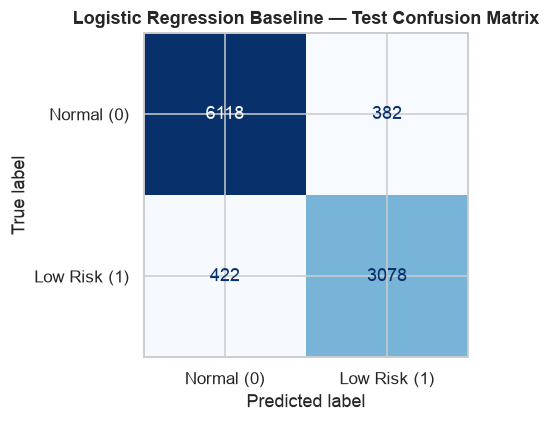

In [7]:
cm = confusion_matrix(y_test, sel_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal (0)", "Low Risk (1)"]).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("Logistic Regression Baseline — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 4. Baseline Takeaways

- Both `train.csv` (`40,000` rows) and `test.csv` (`10,000` rows) preserve the exact `35.0%` positive rate (`low_yield_risk = 1`).
- Scaling (`StandardScaler`) and `LogisticRegression` are fit strictly on `train.csv` with zero test leakage.
- All metrics (`Accuracy`, `Precision`, `Recall`, `F1`, `ROC-AUC`) confirm strong pre-harvest discrimination using only pre-season signals (`rainfall_mm`, `temperature_c`, `fertilizer_used`, `irrigation_used` plus the 4 engineered terms).